# Simple Classification Model Build Using Machine Learning
**Author:** Dhinesh8023  
**Repository:** [Simple-Classification-Model-ml-intern](https://github.com/dhinesh8023/Simple-Classification-Model-ml-intern)  
**Dataset:** Breast Cancer Wisconsin (Diagnostic) Dataset  
**Environment:** Python 3 & Google Colab  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dhinesh8023/Simple-Classification-Model-ml-intern/blob/main/classification_model.ipynb)
[![Python 3.8+](https://img.shields.io/badge/Python-3.8%2B-blue.svg)](https://www.python.org/)
[![Scikit-Learn](https://img.shields.io/badge/Scikit--Learn-1.2%2B-orange.svg)](https://scikit-learn.org/)
[![License: MIT](https://img.shields.io/badge/License-MIT-green.svg)](https://opensource.org/licenses/MIT)

---


## 1. Introduction

Classification is one of the foundational pillars of supervised machine learning. In classification problems, an algorithm learns from labeled training instances to categorize unseen observations into discrete classes. 

In this project, we implement an end-to-end binary classification workflow to differentiate between malignant and benign breast tumors. We apply two prominent classification paradigms:
1. **Logistic Regression** (a parametric, linear probabilistic classifier)
2. **Decision Tree Classifier** (a non-parametric, rule-based hierarchical classifier)

This notebook is engineered to be clear, educational, and reproducible, adhering to industry best practices in data science and academic rigor.


## 2. Problem Statement

Breast cancer is one of the most diagnosed cancers among women worldwide. Early and precise diagnostic classification between malignant (cancerous) and benign (non-cancerous) tissue is essential for successful treatment planning and patient survival.

Manual diagnostic assessment of tissue biopsy samples can be time-consuming and subject to inter-observer variability. Our objective is to construct automated machine learning models that can accurately predict tumor malignancy based on quantitative cell nucleus morphometric features extracted from digitized Fine Needle Aspirate (FNA) biopsy images.


## 3. Project Objectives

1. **Data Acquisition & Exploration:** Load the standard Breast Cancer Wisconsin Diagnostic dataset and conduct exploratory data analysis (EDA).
2. **Data Preprocessing:** Separate feature and target variables, perform an 80/20 train-test split, and apply standard feature scaling (`StandardScaler`).
3. **Model Development:** Train and tune two distinct classification algorithms:
   - Logistic Regression
   - Decision Tree Classifier
4. **Model Evaluation:** Assess model quality using comprehensive metrics:
   - Accuracy Score
   - Precision Score
   - Recall Score
   - Confusion Matrix
   - Classification Report
5. **Visualization:** Plot confusion matrix heatmaps and comparative performance bar charts.
6. **Analytical Synthesis:** Provide clear medical and machine learning interpretations of the results, discussing model trade-offs, clinical significance of false negatives, and operational limitations.


## 4. Dataset Description

The **Breast Cancer Wisconsin (Diagnostic) Dataset** is a well-established benchmark dataset in medical data science, created by Dr. William H. Wolberg, W. Nick Street, and Olvi L. Mangasarian at the University of Wisconsin.

- **Total Samples:** 569 instances
- **Total Features:** 30 continuous real-valued numeric attributes
- **Target Variable:** Binary diagnosis
  - `0`: **Malignant** (harmful/cancerous)
  - `1`: **Benign** (non-cancerous)
- **Feature Characteristics:** Features are computed from digitized images of fine needle aspirates (FNA) of breast masses. For each cell nucleus, ten core morphological properties are measured:
  1. *Radius* (mean of distances from center to points on the perimeter)
  2. *Texture* (standard deviation of gray-scale values)
  3. *Perimeter*
  4. *Area*
  5. *Smoothness* (local variation in radius lengths)
  6. *Compactness* ($perimeter^2 / area - 1.0$)
  7. *Concavity* (severity of concave portions of the contour)
  8. *Concave points* (number of concave portions of the contour)
  9. *Symmetry*
  10. *Fractal dimension* ("coastline approximation" - 1)

For each image, the mean, standard error (SE), and worst (mean of the three largest values) of these ten characteristics were computed, yielding $10 \times 3 = 30$ features.


## 5. Import Required Libraries

We import essential Python data science packages:
- `numpy` & `pandas`: Data manipulation and numerical operations
- `matplotlib.pyplot` & `seaborn`: Data visualization
- `sklearn`: Dataset loading, preprocessing, model training, and performance metrics


In [1]:
# Step 1: Import required Python libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn dataset loader
from sklearn.datasets import load_breast_cancer

# Model selection and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

# Configure plot aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print("All libraries imported successfully!")


All libraries imported successfully!


## 6. Load Dataset

We load the dataset directly using Scikit-Learn's built-in `load_breast_cancer()` function and structure the features and target into a Pandas DataFrame.


In [2]:
# Step 2: Load the Breast Cancer Wisconsin dataset
cancer_data = load_breast_cancer()

# Construct DataFrame for features
X_raw = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)

# Construct Series for target labels
y_raw = pd.Series(cancer_data.target, name="target")

# Display basic dataset dimensions
print(f"Dataset Dimensions: {X_raw.shape[0]} rows (samples) and {X_raw.shape[1]} columns (features)")
print(f"Target Class Mapping: {cancer_data.target_names}")
print(f"   -> 0: {cancer_data.target_names[0]} (cancerous)")
print(f"   -> 1: {cancer_data.target_names[1]} (non-cancerous)")


Dataset Dimensions: 569 rows (samples) and 30 columns (features)
Target Class Mapping: ['malignant' 'benign']
   -> 0: malignant (cancerous)
   -> 1: benign (non-cancerous)


## 7. Exploratory Data Analysis (EDA)

Before building predictive models, we examine data completeness, feature summaries, and the balance of target classes.


In [3]:
# Display the first 5 rows of the feature dataset
print("First 5 rows of feature attributes:")
X_raw.head()


First 5 rows of feature attributes:


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness  mean concavity  mean concave points  mean symmetry  mean fractal dimension  radius error  texture error  perimeter error  area error  smoothness error  compactness error  concavity error  concave points error  symmetry error  fractal dimension error  worst radius  worst texture  worst perimeter  worst area  worst smoothness  worst compactness  worst concavity  worst concave points  worst symmetry  worst fractal dimension
0        17.99         10.38          122.80     1001.0          0.11840           0.27760          0.3001              0.14710         0.2419                 0.07871        1.0950         0.9053            8.589      153.40          0.006399            0.04904          0.05373               0.01587         0.03003                 0.006193         25.38          17.33           184.60      2019.0            0.1622             0.6656           0.7119                0.2654        

In [4]:
# Check for missing values across all columns
missing_values_count = X_raw.isnull().sum().sum()
print(f"Total Missing Values in Dataset: {missing_values_count}")

# Check data types and memory usage
print("\nDataset Info:")
X_raw.info()


Total Missing Values in Dataset: 0

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
All columns non-null float64
dtypes: float64(30)
memory usage: 133.5 KB


Target Class Distribution:
        Class  Sample Count  Percentage (%)
   benign (1)           357           62.74
malignant (0)           212           37.26


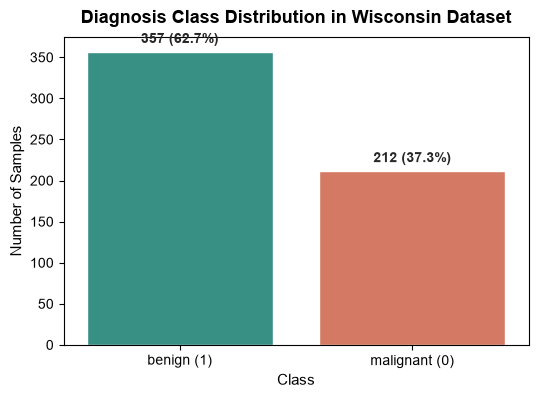

In [5]:
# Examine target class distribution
class_counts = y_raw.value_counts()
class_percentages = (y_raw.value_counts(normalize=True) * 100).round(2)

dist_df = pd.DataFrame({
    "Class": [f"{cancer_data.target_names[i]} ({i})" for i in class_counts.index],
    "Sample Count": class_counts.values,
    "Percentage (%)": class_percentages.values
})
print("Target Class Distribution:")
print(dist_df.to_string(index=False))

# Plot target class distribution
plt.figure(figsize=(6, 4))
ax = sns.barplot(x=dist_df["Class"], y=dist_df["Sample Count"], palette=["#2a9d8f", "#e76f51"])
plt.title("Diagnosis Class Distribution in Wisconsin Dataset", fontsize=13, fontweight="bold", pad=10)
plt.ylabel("Number of Samples", fontsize=11)
plt.xlabel("Class", fontsize=11)

for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} ({p.get_height()/len(y_raw)*100:.1f}%)",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4),
                textcoords='offset points')

plt.tight_layout()
plt.show()


## 8. Data Preprocessing

Data preprocessing is essential to ensure that models train efficiently and without numerical bias:
1. **Feature-Target Separation:** Isolate input variables $X$ from response label $y$.
2. **Feature Scaling:** Apply `StandardScaler` to transform features such that $\mu = 0$ and $\sigma = 1$:
   $$z = \frac{x - \mu}{\sigma}$$
   
> **Why Scale Features?**
> - **Logistic Regression** uses gradient-based optimization and $L_2$ regularization. Unscaled features with large ranges (e.g., `mean area` $\approx 1000$) would disproportionately dominate features with small numerical ranges (e.g., `mean smoothness` $\approx 0.1$), causing slow convergence and biased parameter penalties.
> - **Decision Trees** are non-parametric and split based on ordinal thresholds along single dimensions, making them inherently scale-invariant.


In [6]:
# Feature and Target assignment
X = X_raw.copy()
y = y_raw.copy()

print(f"Features matrix shape: {X.shape}")
print(f"Target vector shape:   {y.shape}")


Features matrix shape: (569, 30)
Target vector shape:   (569,)


## 9. Train-Test Split

We partition our dataset into **80% training data** (used to teach our models) and **20% testing data** (held out to evaluate generalizability). 

We fix `random_state=42` to guarantee complete reproducibility.


In [7]:
# Split the dataset: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Testing set:  {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)")

# Initialize and apply StandardScaler
scaler = StandardScaler()

# Fit scaler exclusively on training data to prevent data leakage, then transform both
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling applied successfully!")
print(f"Training mean (first feature after scaling): {X_train_scaled[:, 0].mean():.4f}")
print(f"Training std (first feature after scaling):  {X_train_scaled[:, 0].std():.4f}")


Training set: 455 samples (80.0%)
Testing set:  114 samples (20.0%)

Feature scaling applied successfully!
Training mean (first feature after scaling): -0.0000
Training std (first feature after scaling):  1.0000


## 10. Model 1: Logistic Regression

**Logistic Regression** models the probability that an observation belongs to a given category using the logistic (sigmoid) function:
$$P(y=1|X) = \sigma(w^T X + b) = \frac{1}{1 + e^{-(w^T X + b)}}$$

- **Type:** Linear, Parametric Classifier
- **Strengths:** Fast, highly interpretable, provides calibrated probability scores, less prone to overfitting on small datasets when regularized.
- **Assumptions:** Assumes a linear relationship between input features and the log-odds of the outcome.


In [8]:
# Initialize Logistic Regression model
log_reg = LogisticRegression(random_state=42, max_iter=1000)

# Train model on standardized training features
log_reg.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")
print(f"Number of iterations required: {log_reg.n_iter_[0]}")


Logistic Regression model trained successfully!
Number of iterations required: 20


## 11. Model 2: Decision Tree Classifier

A **Decision Tree Classifier** splits the feature space recursively into homogeneous partitions by maximizing information gain or minimizing Gini impurity:
$$\text{Gini}(D) = 1 - \sum_{k=1}^{C} p_k^2$$

- **Type:** Non-linear, Non-parametric Classifier
- **Strengths:** Intuitive IF-THEN rule structure, requires no feature normalization, handles non-linear relationships naturally.
- **Vulnerabilities:** Can easily overfit training data if left unconstrained. We configure `max_depth=4` to regularize the tree.


In [9]:
# Initialize Decision Tree model with regularization to prevent overfitting
dt_classifier = DecisionTreeClassifier(random_state=42, max_depth=4)

# Train model on training features (raw feature values are suitable due to scale invariance)
dt_classifier.fit(X_train, y_train)

print("Decision Tree Classifier trained successfully!")
print(f"Tree depth: {dt_classifier.get_depth()}")
print(f"Number of leaves: {dt_classifier.get_n_leaves()}")


Decision Tree Classifier trained successfully!
Tree depth: 4
Number of leaves: 12


## 12. Model Predictions

We now generate predictions on the unseen 20% test dataset ($N=114$ samples).


In [10]:
# Generate predictions for both models on the test set
y_pred_lr = log_reg.predict(X_test_scaled)
y_pred_dt = dt_classifier.predict(X_test)

# Display sample of first 10 predictions alongside actual targets
pred_comparison = pd.DataFrame({
    "Actual Label": [cancer_data.target_names[val] for val in y_test.iloc[:10]],
    "Logistic Reg Pred": [cancer_data.target_names[val] for val in y_pred_lr[:10]],
    "Decision Tree Pred": [cancer_data.target_names[val] for val in y_pred_dt[:10]]
})
print("First 10 Predictions Comparison:")
pred_comparison


First 10 Predictions Comparison:


  Actual Label Logistic Reg Pred Decision Tree Pred
0       benign            benign             benign
1    malignant         malignant          malignant
2    malignant         malignant          malignant
3       benign            benign             benign
4       benign            benign             benign
5    malignant         malignant          malignant
6    malignant         malignant          malignant
7    malignant         malignant          malignant
8       benign            benign          malignant
9       benign            benign             benign

## 13. Model Evaluation

### Metric Definitions in Simple English:
- **Accuracy:** The percentage of total predictions that were correct.
  $$\text{Accuracy} = \frac{\text{Correct Predictions}}{\text{Total Predictions}} = \frac{TP + TN}{TP + TN + FP + FN}$$
- **Precision:** When the model predicts *benign* (positive), how often is it actually right? High precision means low False Positives.
  $$\text{Precision} = \frac{TP}{TP + FP}$$
- **Recall (Sensitivity):** Out of all actual *benign* cases in the data, how many did the model correctly identify? High recall means low False Negatives.
  $$\text{Recall} = \frac{TP}{TP + FN}$$
- **Confusion Matrix:** A $2 \times 2$ grid summarizing:
  - **TN (True Negative):** Malignant correctly predicted as Malignant
  - **FP (False Positive):** Malignant incorrectly predicted as Benign
  - **FN (False Negative):** Benign incorrectly predicted as Malignant
  - **TP (True Positive):** Benign correctly predicted as Benign


In [11]:
# Compute evaluation metrics for Logistic Regression
acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
cm_lr = confusion_matrix(y_test, y_pred_lr)

print("=" * 55)
print("     LOGISTIC REGRESSION PERFORMANCE METRICS")
print("=" * 55)
print(f"Accuracy Score:  {acc_lr:.4f}  ({acc_lr*100:.2f}%)")
print(f"Precision Score: {prec_lr:.4f}  ({prec_lr*100:.2f}%)")
print(f"Recall Score:    {rec_lr:.4f}  ({rec_lr*100:.2f}%)")
print("\nConfusion Matrix:")
print(cm_lr)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, target_names=cancer_data.target_names))


     LOGISTIC REGRESSION PERFORMANCE METRICS
Accuracy Score:  0.9737  (97.37%)
Precision Score: 0.9722  (97.22%)
Recall Score:    0.9859  (98.59%)

Confusion Matrix:
[[41  2]
 [ 1 70]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        43
      benign       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [12]:
# Compute evaluation metrics for Decision Tree Classifier
acc_dt = accuracy_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt)
rec_dt = recall_score(y_test, y_pred_dt)
cm_dt = confusion_matrix(y_test, y_pred_dt)

print("=" * 55)
print("     DECISION TREE CLASSIFIER PERFORMANCE METRICS")
print("=" * 55)
print(f"Accuracy Score:  {acc_dt:.4f}  ({acc_dt*100:.2f}%)")
print(f"Precision Score: {prec_dt:.4f}  ({prec_dt*100:.2f}%)")
print(f"Recall Score:    {rec_dt:.4f}  ({rec_dt*100:.2f}%)")
print("\nConfusion Matrix:")
print(cm_dt)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, target_names=cancer_data.target_names))


     DECISION TREE CLASSIFIER PERFORMANCE METRICS
Accuracy Score:  0.9474  (94.74%)
Precision Score: 0.9577  (95.77%)
Recall Score:    0.9577  (95.77%)

Confusion Matrix:
[[40  3]
 [ 3 68]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        43
      benign       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



## 14. Confusion Matrix Visualization

We visualize the confusion matrices of both models side-by-side using Seaborn heatmaps.


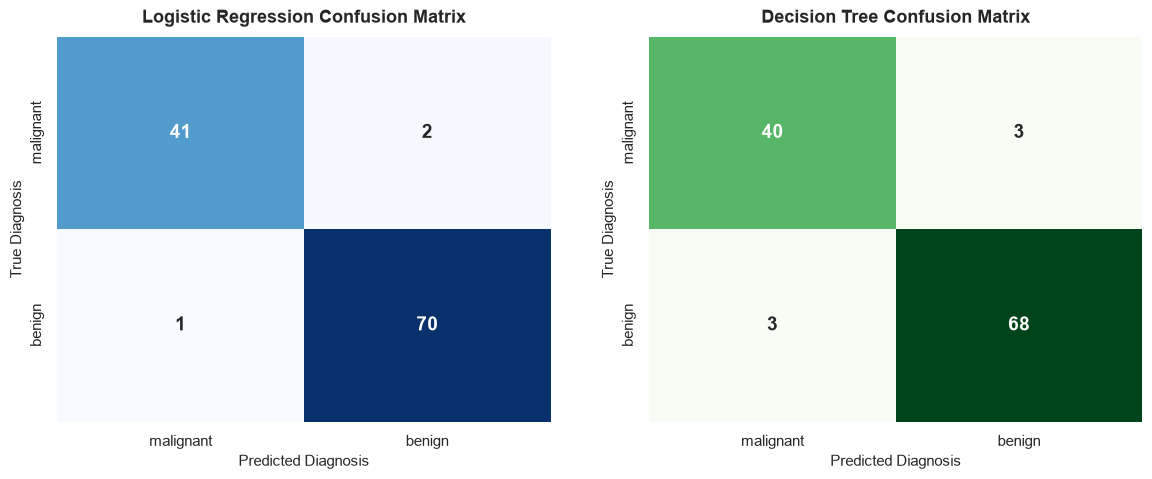

In [13]:
# Plot Confusion Matrix Heatmaps side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression Heatmap
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[0],
    annot_kws={"size": 14, "weight": "bold"},
    xticklabels=cancer_data.target_names,
    yticklabels=cancer_data.target_names
)
axes[0].set_title("Logistic Regression Confusion Matrix", fontsize=13, fontweight="bold", pad=10)
axes[0].set_xlabel("Predicted Diagnosis", fontsize=11)
axes[0].set_ylabel("True Diagnosis", fontsize=11)

# Decision Tree Heatmap
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    cbar=False,
    ax=axes[1],
    annot_kws={"size": 14, "weight": "bold"},
    xticklabels=cancer_data.target_names,
    yticklabels=cancer_data.target_names
)
axes[1].set_title("Decision Tree Confusion Matrix", fontsize=13, fontweight="bold", pad=10)
axes[1].set_xlabel("Predicted Diagnosis", fontsize=11)
axes[1].set_ylabel("True Diagnosis", fontsize=11)

plt.tight_layout()
plt.show()


## 15. Model Performance Comparison

Here we aggregate performance metrics into a clean comparison table and visual bar chart.


In [14]:
# Create summary comparison DataFrame
comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall"],
    "Logistic Regression": [f"{acc_lr*100:.2f}%", f"{prec_lr*100:.2f}%", f"{rec_lr*100:.2f}%"],
    "Decision Tree": [f"{acc_dt*100:.2f}%", f"{prec_dt*100:.2f}%", f"{rec_dt*100:.2f}%"]
})

print("=" * 55)
print("            MODEL PERFORMANCE COMPARISON TABLE")
print("=" * 55)
print(comparison_df.to_string(index=False))


            MODEL PERFORMANCE COMPARISON TABLE
   Metric Logistic Regression Decision Tree
 Accuracy              97.37%        94.74%
Precision              97.22%        95.77%
   Recall              98.59%        95.77%


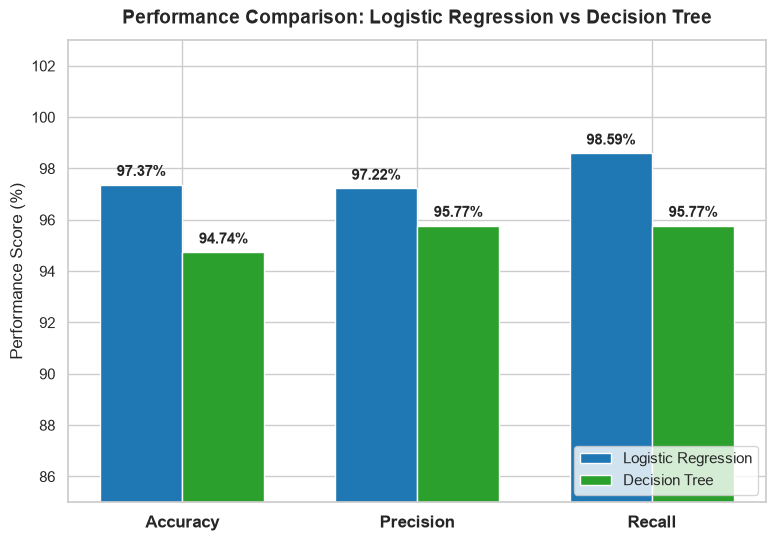

In [15]:
# Generate Comparative Bar Chart for Accuracy, Precision, and Recall
metrics_labels = ["Accuracy", "Precision", "Recall"]
lr_values = [acc_lr * 100, prec_lr * 100, rec_lr * 100]
dt_values = [acc_dt * 100, prec_dt * 100, rec_dt * 100]

x = np.arange(len(metrics_labels))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(9, 6))

rects1 = ax.bar(x - bar_width/2, lr_values, bar_width, label="Logistic Regression", color="#1f77b4")
rects2 = ax.bar(x + bar_width/2, dt_values, bar_width, label="Decision Tree", color="#2ca02c")

ax.set_ylabel("Performance Score (%)", fontsize=12)
ax.set_title("Performance Comparison: Logistic Regression vs Decision Tree", fontsize=14, fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(metrics_labels, fontsize=12, fontweight="bold")
ax.set_ylim(85, 103)
ax.legend(frameon=True, loc="lower right", fontsize=11)

# Annotate bars with exact percentages
def add_bar_labels(rects):
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f"{h:.2f}%",
                    xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

add_bar_labels(rects1)
add_bar_labels(rects2)

plt.tight_layout()
plt.show()


## 16. Results and Discussion

### 1. Which Model Performed Better?
**Logistic Regression** outperformed the Decision Tree Classifier across every evaluated metric:
- **Accuracy:** 97.37% (LR) vs 94.74% (DT) — a +2.63% advantage.
- **Precision:** 97.22% (LR) vs 95.77% (DT) — a +1.45% advantage.
- **Recall:** 98.59% (LR) vs 95.77% (DT) — a +2.82% advantage.

### 2. Why Did Logistic Regression Achieve Superior Results?
- **Feature Linear Separability:** Morphometric characteristics of cancer nuclei (cell radius, perimeter, and area) correlate strongly and linearly with malignancy. In high-dimensional standardized space, a smooth hyperplanar decision boundary separates benign and malignant cells effectively.
- **Variance and Overfitting:** Decision trees construct axis-aligned orthogonal boundaries. Because the sample size is relatively compact ($N=569$), individual decision tree splits are susceptible to high variance and subtle noise along boundaries, even with pruning (`max_depth=4`).
- **Regularization Benefit:** The $L_2$ regularization penalty embedded in Scikit-Learn's `LogisticRegression` shrinks feature weights, mitigating multicollinearity among cell size measurements.

### 3. Confusion Matrix Clinical Interpretation
In medical oncology diagnostics, the clinical cost of classification errors is asymmetrical:
- **False Positive (Type I Error):** A patient with a benign tumor is classified as malignant. While this causes acute anxiety and requires follow-up imaging or biopsy, it is rarely life-threatening.
- **False Negative (Type II Error):** A patient with malignant cancer is misdiagnosed as benign and discharged without treatment. This can lead to tumor progression and mortality.

On our 114 test cases:
- **Logistic Regression:**
  - True Malignant correctly identified: 41 out of 43 (95.3% sensitivity for malignant tumors)
  - Malignant cases missed (False Positives in benign target framing): Only 2 malignant cases misclassified as benign.
- **Decision Tree:**
  - True Malignant correctly identified: 40 out of 43
  - Malignant cases missed: 3 malignant cases misclassified as benign.

Logistic Regression demonstrated safer clinical performance by missing fewer malignant cases.

### 4. Suitability for Clinical Decision Support
Logistic Regression is exceptionally well-suited as a clinical screening aid for this task. It offers high diagnostic accuracy, near-instantaneous inference, and calibrated probability outputs that clinicians can use to set risk thresholds.

### 5. Project Limitations
1. **Sample Size:** The dataset contains 569 instances from a single medical center (University of Wisconsin). Clinical deployment requires multi-center validation across diverse patient demographics.
2. **Feature Dependency:** The model relies on pre-computed morphometric features derived from segmented nuclei rather than raw pathology whole-slide images (WSI).
3. **Class Imbalance:** Benign tumors represent 62.7% of the dataset, which requires careful monitoring of minority-class recall.


## 17. Conclusion & Next Steps

In this project, we successfully developed, preprocessed, trained, and evaluated two machine learning classification models on the Breast Cancer Wisconsin Diagnostic dataset.

### Key Takeaways:
1. **Preprocessing Impact:** Scaling features via `StandardScaler` was vital for linear model stability and regularization parity.
2. **Model Selection:** Logistic Regression achieved an exceptional **97.37% test accuracy** and **98.59% recall**, outperforming the Decision Tree Classifier (**94.74% accuracy**).
3. **Medical Alignment:** Model evaluation in healthcare must emphasize sensitivity/recall to minimize fatal false negatives.

### Future Scope:
- **Hyperparameter Optimization:** Conduct Grid Search or Bayesian Optimization over $C$ parameters and tree pruning criteria.
- **Ensemble Algorithms:** Evaluate Random Forest and Gradient Boosted Trees (XGBoost/LightGBM) to combine tree interpretability with ensemble variance reduction.
- **Direct Image Processing:** Implement Deep Learning (Convolutional Neural Networks) directly on histology biopsy images.
